In [1]:
from ase.io import read, write
from ase import units
import numpy as np
from imolcraft.crafter.ffxml import merge_xml
from imolcraft.trainer import DistanceTrainer
from imolcraft.calculator.distance import DistanceCalculator
from imolcraft.trainer.loss import loss_energy
from functools import partial

Warning on use of the timeseries module: If the inherent timescales of the system are long compared to those being analyzed, this statistical inefficiency may be an underestimate.  The estimate presumes the use of many statistically independent samples.  Tests should be performed to assess whether this condition is satisfied.   Be cautious in the interpretation of the data.


In [2]:
atoms_snli = read("SNLi.log")

In [3]:
merged_xml = merge_xml(["SN.xml", "Li.xml"], "merged.xml")  # written to xmlfiles/merged.xml

In [4]:
calculator = DistanceCalculator(
    atoms_snli,
    1,
    "cn__Li",
    scan_idx=[[5,10]],
    directory="distance_scan",
    qmparams={
             "method": "wb97xd",
             "basis": "6-31g(d)",
             "opt": "modredundant",
             }
)

In [5]:
import glob

g16logs = glob.glob("distance_scan/*.log")

for i, g16log in enumerate(g16logs):
    atoms = read(g16log)
    distance = atoms.get_distance(5, 10)
    energy = atoms.get_potential_energy()/(units.kJ / units.mol)
    calculator.qm_scan[0]["distance_A"].append(distance)
    calculator.qm_scan[0]["energy_kjmol"].append(energy)
    calculator.qm_scan[0]["atoms"].append(atoms)

In [6]:
# calculator.qm_scan[0]でcalculator.qm_scan[0]["distance_A"]ベースでソート
# "distance_A"の値で全リストをソート
order = np.argsort(calculator.qm_scan[0]["distance_A"])
for key in calculator.qm_scan[0]:
	calculator.qm_scan[0][key] = [calculator.qm_scan[0][key][i] for i in order]

In [7]:
calculator.do_ffscan(merged_xml)

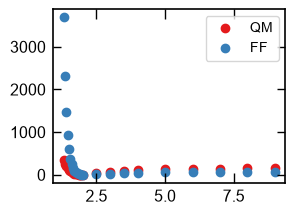

In [8]:
import numpy as np
import matplotlib.pyplot as plt

plt.scatter(calculator.qm_scan[0]["distance_A"], np.array(calculator.qm_scan[0]["energy_kjmol"])-np.array(calculator.qm_scan[0]["energy_kjmol"]).min(), label="QM")

plt.scatter(calculator.ff_scan[0]["distance_A"], np.array(calculator.ff_scan[0]["energy_kjmol"])-np.array(calculator.ff_scan[0]["energy_kjmol"]).min(), label="FF")

plt.legend()

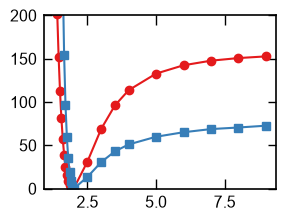

In [9]:
plt.ylim(0,200)
plt.plot(calculator.qm_scan[0]["distance_A"], np.array(calculator.qm_scan[0]["energy_kjmol"])-min(calculator.qm_scan[0]["energy_kjmol"]), marker="o")
plt.plot(calculator.ff_scan[0]["distance_A"], np.array(calculator.ff_scan[0]["energy_kjmol"])-min(calculator.ff_scan[0]["energy_kjmol"]), marker="s")

In [10]:
lossfn = partial(loss_energy, weight_scheme="boltzmann", zeropoint="qmmin")

In [11]:
dtrainer = DistanceTrainer(ffxml_list=["SN.xml", "Li.xml"], 
                           nums_ffxml=[1,1], 
                           pdbfile="initial.pdb", 
                           calculator=calculator,
                           loss_fn=lossfn,
                           opt_fftypes=["NonbondedForce/charge", "VirtualSite/vsite_w2_type_2"],
                           lr=0.0005)

In [12]:
dtrainer.ffparams

{'HarmonicBondForce': {'length': Array([0.1153, 0.1467, 0.1538, 0.1097], dtype=float64),
  'k': Array([746040.672, 247575.648, 194572.736, 314569.856], dtype=float64)},
 'HarmonicAngleForce': {'angle': Array([3.11680898, 1.94970731, 1.90956473, 1.91637152, 1.87762521],      dtype=float64),
  'k': Array([612.671488, 554.597568, 409.019472, 391.756288, 326.01728 ],      dtype=float64)},
 'PeriodicTorsionForce': {'proper_phase': Array([3.14159265, 3.14159265, 0.        , 0.        , 0.        ],      dtype=float64),
  'proper_k': Array([0.        , 0.        , 0.65084444, 0.65084444, 0.50208   ],      dtype=float64),
  'improper_phase': Array([], shape=(0,), dtype=float64),
  'improper_k': Array([], shape=(0,), dtype=float64)},
 'NonbondedForce': {'sigma': Array([0.32735182, 0.34789595, 0.33977095, 0.2600177 , 0.1       ,
         0.20259037], dtype=float64),
  'epsilon': Array([0.4594032, 0.6677664, 0.4510352, 0.0870272, 0.       , 0.0765672],      dtype=float64),
  'charge': Array([-0.4

In [13]:
from imolcraft.trainer.dmff_utils import neutralize

def grad_modify(grads):
    # keep the Li charge fixed
    grads["NonbondedForce"]["charge"] = grads["NonbondedForce"]["charge"].at[12].set(0.0)
    # the two average2 sites (M1, M2) of SN are equivalent: give them the same
    # gradient of weight2 (weight1 = 1 - weight2 follows)
    w2 = grads["VirtualSite"]["vsite_w2_type_2"]
    ave_w2 = (w2[0] + w2[1]) / 2
    grads["VirtualSite"]["vsite_w2_type_2"] = w2.at[0].set(ave_w2).at[1].set(ave_w2)
    return grads

def ffparams_modify(ffparams):
    ffparams = neutralize(ffparams, dtrainer.natoms_list, nc=0.8, target_lists=[[0,1,2,3,4,5,6,7,8,9,10,11]], target_charges=[0.0])

    return ffparams

In [14]:
dtrainer.add_modifyfn("after_grad", grad_modify)
dtrainer.add_modifyfn("after_update", ffparams_modify)

In [15]:
dtrainer.setup()

/Users/srak/miniconda3/envs/imc_cpu/lib/python3.11/site-packages/dmff/common/nblist.py:306: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=2`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  nblist = np.array(list(permutations(range(natoms), 2)), dtype=np.dtype(int, 2))


In [16]:
dtrainer.ffparams

{'HarmonicBondForce': {'length': Array([0.1153, 0.1467, 0.1538, 0.1097], dtype=float64),
  'k': Array([746040.672, 247575.648, 194572.736, 314569.856], dtype=float64)},
 'HarmonicAngleForce': {'angle': Array([3.11680898, 1.94970731, 1.90956473, 1.91637152, 1.87762521],      dtype=float64),
  'k': Array([612.671488, 554.597568, 409.019472, 391.756288, 326.01728 ],      dtype=float64)},
 'PeriodicTorsionForce': {'proper_phase': Array([3.14159265, 3.14159265, 0.        , 0.        , 0.        ],      dtype=float64),
  'proper_k': Array([0.        , 0.        , 0.65084444, 0.65084444, 0.50208   ],      dtype=float64),
  'improper_phase': Array([], shape=(0,), dtype=float64),
  'improper_k': Array([], shape=(0,), dtype=float64)},
 'NonbondedForce': {'sigma': Array([0.32735182, 0.34789595, 0.33977095, 0.2600177 , 0.1       ,
         0.20259037], dtype=float64),
  'epsilon': Array([0.4594032, 0.6677664, 0.4510352, 0.0870272, 0.       , 0.0765672],      dtype=float64),
  'charge': Array([-0.4

In [17]:
dtrainer.fit(steps=200, checkpoint_frequency=10)

grad obtained.... Memory Usage: 999.03 MB


grad modify.... Memory Usage: 1008.91 MB


update finished.... Memory Usage: 1075.84 MB
Epoch 0, Loss: 0.008487318455167139, Memory Usage: 1077.23 MB
Loss:  0.008487318455167139
Best Loss:  0.008487318455167139 at epoch  0
Epoch 0 completed in 3.93 seconds.
----
grad obtained.... Memory Usage: 1077.73 MB
grad modify.... Memory Usage: 1077.75 MB
update finished.... Memory Usage: 1077.75 MB
Loss:  0.008487318333254786
Best Loss:  0.008487318333254786 at epoch  1
Epoch 1 completed in 0.04 seconds.
----
grad obtained.... Memory Usage: 1078.75 MB
grad modify.... Memory Usage: 1078.75 MB
update finished.... Memory Usage: 1078.75 MB
Loss:  0.008487318211340697
Best Loss:  0.008487318211340697 at epoch  2
Epoch 2 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1078.91 MB
grad modify.... Memory Usage: 1078.91 MB
update finished.... Memory Usage: 1078.97 MB
Loss:  0.00848731806713255
Best Loss:  0.00848731806713255 at epoch  3
Epoch 3 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1079.11 MB
grad modify..

update finished.... Memory Usage: 1079.36 MB
Loss:  0.008487317531649028
Best Loss:  0.008487317531649028 at epoch  5
Epoch 5 completed in 0.03 seconds.
----
grad obtained.... Memory Usage: 1079.58 MB
grad modify.... Memory Usage: 1079.59 MB
update finished.... Memory Usage: 1079.59 MB
Loss:  0.008487316983766072
Best Loss:  0.008487316983766072 at epoch  6
Epoch 6 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1079.69 MB
grad modify.... Memory Usage: 1079.69 MB
update finished.... Memory Usage: 1079.78 MB
Loss:  0.00848731606787192
Best Loss:  0.00848731606787192 at epoch  7
Epoch 7 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1080.17 MB
grad modify.... Memory Usage: 1080.17 MB
update finished.... Memory Usage: 1080.20 MB
Loss:  0.008487314546864404
Best Loss:  0.008487314546864404 at epoch  8
Epoch 8 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1080.23 MB
grad modify.... Memory Usage: 1080.23 MB
update finished.... Memory Usage: 

update finished.... Memory Usage: 1080.67 MB
Loss:  0.008487256955987866
Best Loss:  0.008487256955987866 at epoch  14
Epoch 14 completed in 0.03 seconds.
----
grad obtained.... Memory Usage: 1080.67 MB
grad modify.... Memory Usage: 1080.67 MB
update finished.... Memory Usage: 1080.69 MB
Loss:  0.008487228492471034
Best Loss:  0.008487228492471034 at epoch  15
Epoch 15 completed in 0.03 seconds.
----
grad obtained.... Memory Usage: 1080.75 MB
grad modify.... Memory Usage: 1080.75 MB
update finished.... Memory Usage: 1080.75 MB
Loss:  0.008487190386622042
Best Loss:  0.008487190386622042 at epoch  16
Epoch 16 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1080.88 MB
grad modify.... Memory Usage: 1080.88 MB
update finished.... Memory Usage: 1080.88 MB
Loss:  0.008487140805293853
Best Loss:  0.008487140805293853 at epoch  17
Epoch 17 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1081.02 MB
grad modify.... Memory Usage: 1081.02 MB
update finished.... Memo

...

Loss:  0.00927448671112896
Best Loss:  0.008333857224289944 at epoch  120
Epoch 159 completed in 5.18 seconds.
----
grad obtained.... Memory Usage: 1016.73 MB
grad modify.... Memory Usage: 1016.73 MB
update finished.... Memory Usage: 1016.73 MB
Epoch 160, Loss: 0.009422519386596058, Memory Usage: 1016.73 MB
Loss:  0.009422519386596058
Best Loss:  0.008333857224289944 at epoch  120
Epoch 160 completed in 0.03 seconds.
----
grad obtained.... Memory Usage: 1016.77 MB
grad modify.... Memory Usage: 1016.77 MB
update finished.... Memory Usage: 1016.77 MB
Loss:  0.00942660453202376
Best Loss:  0.008333857224289944 at epoch  120
Epoch 161 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1016.77 MB
grad modify.... Memory Usage: 1016.77 MB
update finished.... Memory Usage: 1016.77 MB
Loss:  0.009430839116888233
Best Loss:  0.008333857224289944 at epoch  120
Epoch 162 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1016.77 MB
grad modify.... Memory Usage: 1016.77 MB

grad obtained.... Memory Usage: 1016.98 MB
grad modify.... Memory Usage: 1016.98 MB
update finished.... Memory Usage: 1016.98 MB
Loss:  0.009473219523050023
Best Loss:  0.008333857224289944 at epoch  120
Epoch 171 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1016.98 MB
grad modify.... Memory Usage: 1016.98 MB
update finished.... Memory Usage: 1016.98 MB
Loss:  0.009478205464123006
Best Loss:  0.008333857224289944 at epoch  120
Epoch 172 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1016.98 MB
grad modify.... Memory Usage: 1016.98 MB
update finished.... Memory Usage: 1016.98 MB
Loss:  0.00948321875036239
Best Loss:  0.008333857224289944 at epoch  120
Epoch 173 completed in 0.04 seconds.
----
grad obtained.... Memory Usage: 1016.98 MB
grad modify.... Memory Usage: 1016.98 MB
update finished.... Memory Usage: 1017.00 MB
Loss:  0.009488254063076325
Best Loss:  0.008333857224289944 at epoch  120
Epoch 174 completed in 0.02 seconds.
----
grad obtained....

Loss:  0.009513612113590544
Best Loss:  0.008333857224289944 at epoch  120
Epoch 179 completed in 6.13 seconds.
----
grad obtained.... Memory Usage: 1034.61 MB
grad modify.... Memory Usage: 1034.61 MB
update finished.... Memory Usage: 1034.61 MB
Epoch 180, Loss: 0.009335821002098853, Memory Usage: 1034.62 MB
Loss:  0.009335821002098853
Best Loss:  0.008333857224289944 at epoch  120
Epoch 180 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1034.70 MB
grad modify.... Memory Usage: 1034.70 MB
update finished.... Memory Usage: 1034.70 MB
Loss:  0.009340743554290713
Best Loss:  0.008333857224289944 at epoch  120
Epoch 181 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 1034.70 MB
grad modify.... Memory Usage: 1034.70 MB
update finished.... Memory Usage: 1034.70 MB
Loss:  0.009345515232941878
Best Loss:  0.008333857224289944 at epoch  120
Epoch 182 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1034.80 MB
grad modify.... Memory Usage: 1034.80 

grad obtained.... Memory Usage: 1035.05 MB
grad modify.... Memory Usage: 1035.05 MB
update finished.... Memory Usage: 1035.05 MB
Loss:  0.009391340832143252
Best Loss:  0.008333857224289944 at epoch  120
Epoch 193 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 1035.09 MB
grad modify.... Memory Usage: 1035.09 MB
update finished.... Memory Usage: 1035.09 MB
Loss:  0.009395110971338978
Best Loss:  0.008333857224289944 at epoch  120
Epoch 194 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 1035.12 MB
grad modify.... Memory Usage: 1035.12 MB
update finished.... Memory Usage: 1035.12 MB
Loss:  0.009398839143872495
Best Loss:  0.008333857224289944 at epoch  120
Epoch 195 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 1035.14 MB
grad modify.... Memory Usage: 1035.14 MB
update finished.... Memory Usage: 1035.14 MB
Loss:  0.009402529049226395
Best Loss:  0.008333857224289944 at epoch  120
Epoch 196 completed in 0.01 seconds.
----
grad obtained...

Loss:  0.00941340072735137
Best Loss:  0.008333857224289944 at epoch  120
Epoch 199 completed in 3.76 seconds.
----


In [18]:
dtrainer.losses

[Array(0.00848732, dtype=float64),
 Array(0.00848732, dtype=float64),
 Array(0.00848732, dtype=float64),
 Array(0.00848732, dtype=float64),
 Array(0.00848732, dtype=float64),
 Array(0.00848732, dtype=float64),
 Array(0.00848732, dtype=float64),
 Array(0.00848732, dtype=float64),
 Array(0.00848731, dtype=float64),
 Array(0.00848731, dtype=float64),
 Array(0.00848731, dtype=float64),
 Array(0.0084873, dtype=float64),
 Array(0.00848729, dtype=float64),
 Array(0.00848728, dtype=float64),
 Array(0.00848726, dtype=float64),
 Array(0.00848723, dtype=float64),
 Array(0.00848719, dtype=float64),
 Array(0.00848714, dtype=float64),
 Array(0.00848708, dtype=float64),
 Array(0.008487, dtype=float64),
 Array(0.00911976, dtype=float64),
 Array(0.00912007, dtype=float64),
 Array(0.00912072, dtype=float64),
 Array(0.00912165, dtype=float64),
 Array(0.00912279, dtype=float64),
 Array(0.00912412, dtype=float64),
 Array(0.0091256, dtype=float64),
 Array(0.0091272, dtype=float64),
 Array(0.0091289, dtype=f

In [19]:
dtrainer.epochs

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 35,
 36,
 37,
 38,
 39,
 40,
 41,
 42,
 43,
 44,
 45,
 46,
 47,
 48,
 49,
 50,
 51,
 52,
 53,
 54,
 55,
 56,
 57,
 58,
 59,
 60,
 61,
 62,
 63,
 64,
 65,
 66,
 67,
 68,
 69,
 70,
 71,
 72,
 73,
 74,
 75,
 76,
 77,
 78,
 79,
 80,
 81,
 82,
 83,
 84,
 85,
 86,
 87,
 88,
 89,
 90,
 91,
 92,
 93,
 94,
 95,
 96,
 97,
 98,
 99,
 100,
 101,
 102,
 103,
 104,
 105,
 106,
 107,
 108,
 109,
 110,
 111,
 112,
 113,
 114,
 115,
 116,
 117,
 118,
 119,
 120,
 121,
 122,
 123,
 124,
 125,
 126,
 127,
 128,
 129,
 130,
 131,
 132,
 133,
 134,
 135,
 136,
 137,
 138,
 139,
 140,
 141,
 142,
 143,
 144,
 145,
 146,
 147,
 148,
 149,
 150,
 151,
 152,
 153,
 154,
 155,
 156,
 157,
 158,
 159,
 160,
 161,
 162,
 163,
 164,
 165,
 166,
 167,
 168,
 169,
 170,
 171,
 172,
 173,
 174,
 175,
 176,
 177,
 178,
 179,
 180,
 181,
 182,
 183,
 184,


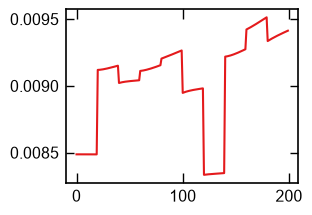

In [20]:
plt.plot(dtrainer.epochs, dtrainer.losses)

In [21]:
idx = np.argmin(dtrainer.losses)
print(dtrainer.epochs[idx], dtrainer.losses[idx])

120 0.008333857224289944


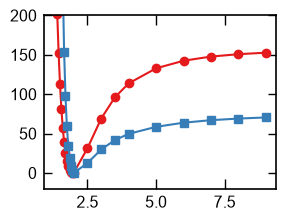

In [22]:
plt.ylim(-20,200)
plt.plot(calculator.qm_scan[0]["distance_A"], np.array(calculator.qm_scan[0]["energy_kjmol"])-min(calculator.qm_scan[0]["energy_kjmol"]), marker="o")
plt.plot(dtrainer.calculator.ff_scan[0]["distance_A"], np.array(dtrainer.calculator.ff_scan[0]["energy_kjmol"])-min(dtrainer.calculator.ff_scan[0]["energy_kjmol"]), marker="s")